In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

sns.set_theme(style="whitegrid")
df = pd.read_csv("C:/Users/hp/Desktop/Practice/Data_Analysis/archive/ecommerce_sales_customer_analytics_150k.csv")

print("Dataset shape:", df.shape)
print("\nFirst 5 rows:")
display(df.head())

print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

Dataset shape: (138116, 46)

First 5 rows:


,order_id,order_date,order_time,order_status,sales_channel,customer_id,customer_name,customer_age,gender,customer_segment,...,discount_amount,tax_amount,shipping_cost,net_sales,product_cost,profit,profit_margin_percentage,customer_lifetime_value,is_repeat_customer,customer_order_count
0,ORD-301242,2023-11-06,16:37:47,Completed,Mobile App,CUST-003102,Jasmine Ryan,55,Male,Consumer,...,477.89,61.07,12.03,945.40,588.33,345.04,36.50,12459.68,True,11
1,ORD-773460,2025-12-24,01:22:36,Completed,Website,CUST-003124,Scott Chase,26,Male,Premium,...,1456.06,320.83,9.00,2018.41,2031.88,-22.47,-1.11,13032.48,True,11
2,ORD-449374,2021-07-05,14:24:21,Completed,Mobile App,CUST-012496,Marc Wheeler,69,Female,Premium,...,97.30,29.79,13.05,468.35,257.73,197.57,42.18,6159.44,True,6
3,ORD-567636,2023-01-21,07:20:26,Completed,Social Media,CUST-023928,Jennifer Smith,65,Male,Consumer,...,53.34,34.39,20.85,546.52,277.84,247.83,45.35,5638.30,True,7
4,ORD-820028,2022-05-13,09:46:21,Completed,Social Media,CUST-012730,Jessica Wang,34,Female,Consumer,...,133.63,421.35,23.03,2785.27,1231.88,1530.36,54.94,13240.10,True,8



Column names:
['order_id', 'order_date', 'order_time', 'order_status', 'sales_channel', 'customer_id', 'customer_name', 'customer_age', 'gender', 'customer_segment', 'customer_type', 'customer_city', 'customer_state', 'customer_country', 'region', 'customer_postal_code', 'payment_method', 'payment_status', 'currency', 'shipping_method', 'warehouse', 'delivery_days', 'estimated_delivery_days', 'delivery_status', 'return_status', 'return_reason', 'customer_rating', 'review_sentiment', 'customer_review', 'marketing_channel', 'campaign_name', 'coupon_code', 'loyalty_points_earned', 'loyalty_points_redeemed', 'quantity', 'gross_sales', 'discount_amount', 'tax_amount', 'shipping_cost', 'net_sales', 'product_cost', 'profit', 'profit_margin_percentage', 'customer_lifetime_value', 'is_repeat_customer', 'customer_order_count']

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 138116 entries, 0 to 138115
Data columns (total 46 columns):
 #   Column                    Non-Null Count   

In [4]:
missing_values = df.isnull().sum().sort_values(ascending=False)
print("Missing values:")
display(missing_values[missing_values > 0])

print("Duplicate rows:", df.duplicated().sum())

print("Duplicate order IDs:", df["order_id"].duplicated().sum())

print("Unique customers:", df["customer_id"].nunique())
print("Unique orders:", df["order_id"].nunique())

for column in ["order_status", "payment_status", "currency"]:
    print(f"\n{column}:")
    print(df[column].value_counts(dropna=False))

df["order_date"] = pd.to_datetime(df["order_date"], errors="coerce")

print("\nInvalid dates:", df["order_date"].isna().sum())

Missing values:


return_reason              128654
return_status              128654
coupon_code                110502
campaign_name               83233
customer_review             24557
customer_rating             24557
estimated_delivery_days     24557
delivery_days               24557
review_sentiment            24557
dtype: int64

Duplicate rows: 0
Duplicate order IDs: 0
Unique customers: 24911
Unique orders: 138116

order_status:
order_status
Completed    113559
Returned       9462
Cancelled      8398
Pending        6697
Name: count, dtype: int64

payment_status:
payment_status
Paid        104250
Pending      13975
Failed       10429
Refunded      9462
Name: count, dtype: int64

currency:
currency
USD    82600
GBP    20235
EUR    11593
CAD     7015
AUD     6794
INR     5707
AED     4172
Name: count, dtype: int64

Invalid dates: 0


In [5]:
df = df.drop_duplicates().copy()

df = df.dropna(
    subset=["order_id", "customer_id", "order_date", "order_status"]
).copy()

for column in ["order_status", "currency"]:
    df[column] = df[column].astype("string").str.strip()

numeric_columns = [
    "net_sales",
    "gross_sales",
    "profit",
    "customer_lifetime_value",
    "customer_order_count"
]

for column in numeric_columns:
    df[column] = pd.to_numeric(df[column], errors="coerce")

df = df.dropna(
    subset=["customer_id", "order_date", "net_sales", "currency"]
).copy()

completed_df = df[
    df["order_status"].str.casefold() == "completed"
].copy()

completed_df = completed_df[
    completed_df["net_sales"] >= 0
].copy()

print("Cleaned dataset shape:", df.shape)
print("Completed transaction rows:", len(completed_df))
print("Customers with completed transactions:",
      completed_df["customer_id"].nunique())

Cleaned dataset shape: (138116, 46)
Completed transaction rows: 113559
Customers with completed transactions: 24748


In [6]:
print("Average purchase value:")
print(round(completed_df["net_sales"].mean(), 2))

print("\nTotal completed sales (raw reported currency amounts):")
print(round(completed_df["net_sales"].sum(), 2))

print("\nAverage profit per completed transaction:")
print(round(completed_df["profit"].mean(), 2))

customer_summary = completed_df.groupby("customer_id").agg(
    purchase_frequency=("order_id", "nunique"),
    total_spending=("net_sales", "sum"),
    average_purchase_value=("net_sales", "mean"),
    customer_lifetime_value=("customer_lifetime_value", "max")
).reset_index()

print("\nCustomer-level descriptive statistics:")
display(customer_summary[
    [
        "purchase_frequency",
        "total_spending",
        "average_purchase_value",
        "customer_lifetime_value"
    ]
].describe().round(2))

Average purchase value:
1269.79

Total completed sales (raw reported currency amounts):
144195838.5

Average profit per completed transaction:
526.23

Customer-level descriptive statistics:


,purchase_frequency,total_spending,average_purchase_value,customer_lifetime_value
count,24748.00,24748.00,24748.00,24748.00
mean,4.59,5826.57,1269.51,7753.19
std,2.08,3629.48,624.00,4250.73
min,1.00,22.55,22.55,22.55
25%,3.00,3098.38,850.32,4593.28
50%,4.00,5225.85,1178.63,7134.22
75%,6.00,7904.70,1583.30,10292.36
max,15.00,27671.95,8874.15,30268.44


In [7]:
reference_date = completed_df["order_date"].max().normalize() + pd.Timedelta(days=1)
print("Reference date:", reference_date.date())

rfm = completed_df.groupby("customer_id").agg(
    last_purchase_date=("order_date", "max"),
    Frequency=("order_id", "nunique"),
    Monetary=("net_sales", "sum"),
    Average_Purchase_Value=("net_sales", "mean"),
    Customer_Lifetime_Value=("customer_lifetime_value", "max"),
    Currency=("currency", "first")
).reset_index()

rfm["Recency"] = (
    reference_date - rfm["last_purchase_date"]
).dt.days

rfm["Monetary_Score"] = (
    rfm.groupby("Currency")["Monetary"]
       .rank(pct=True)
)

display(rfm.head(10))
print("Total customers in RFM table:", len(rfm))

Reference date: 2026-01-01


,customer_id,last_purchase_date,Frequency,Monetary,Average_Purchase_Value,Customer_Lifetime_Value,Currency,Recency,Monetary_Score
0,CUST-000001,2025-12-25,7,9370.54,1338.648571,11125.84,AED,7,0.872562
1,CUST-000002,2025-02-20,7,12713.84,1816.262857,18138.96,EUR,315,0.928783
2,CUST-000003,2025-06-05,6,7664.59,1277.431667,7798.59,EUR,210,0.675074
3,CUST-000004,2025-11-07,4,7382.98,1845.745000,11218.95,USD,55,0.724819
4,CUST-000005,2024-11-14,8,10063.97,1257.996250,10063.97,USD,413,0.887844
5,CUST-000006,2025-03-16,7,9284.89,1326.412857,12963.67,GBP,291,0.799017
6,CUST-000007,2024-09-20,3,7272.75,2424.250000,10679.09,USD,468,0.716431
7,CUST-000008,2025-08-12,5,3794.92,758.984000,4938.79,USD,142,0.346547
8,CUST-000009,2024-05-28,2,496.50,248.250000,2615.45,USD,583,0.021173
9,CUST-000010,2025-10-21,3,4893.34,1631.113333,9556.63,EUR,72,0.400593


Total customers in RFM table: 24748


In [8]:
features = ["Recency", "Frequency", "Monetary_Score"]

X = rfm[features].copy()
print("Missing values:")
print(X.isnull().sum())

print("\nInfinite values:")
print(np.isinf(X).sum())

X = X.replace([np.inf, -np.inf], np.nan)

valid_rows = X.notna().all(axis=1)

rfm = rfm.loc[valid_rows].copy()
X = X.loc[valid_rows].copy()

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Scaled data shape:", X_scaled.shape)
print("Scaled feature means:", X_scaled.mean(axis=0).round(3))
print("Scaled feature standard deviations:", X_scaled.std(axis=0).round(3))

Missing values:
Recency           0
Frequency         0
Monetary_Score    0
dtype: int64

Infinite values:
Recency           0
Frequency         0
Monetary_Score    0
dtype: int64
Scaled data shape: (24748, 3)
Scaled feature means: [-0. -0. -0.]
Scaled feature standard deviations: [1. 1. 1.]


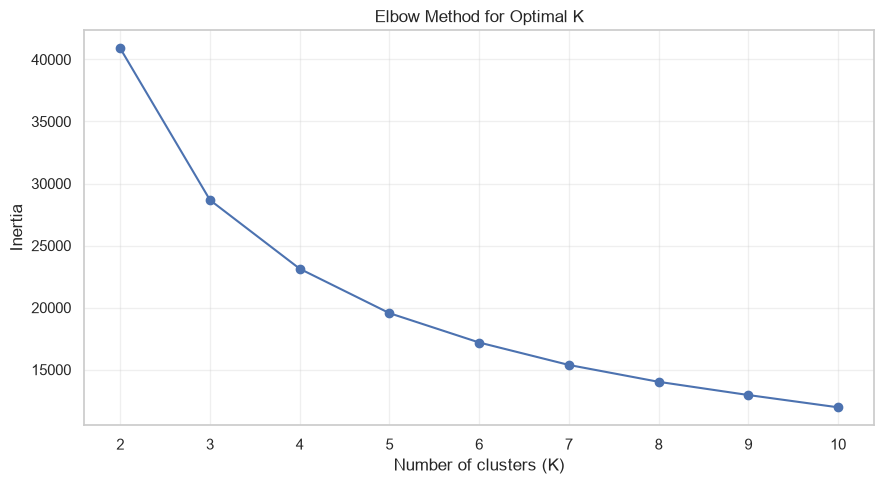

In [9]:
inertia_values = []
k_values = range(2, 11)

for k in k_values:
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    model.fit(X_scaled)
    inertia_values.append(model.inertia_)

plt.figure(figsize=(9, 5))
plt.plot(k_values, inertia_values, marker="o")
plt.xlabel("Number of clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method for Optimal K")
plt.xticks(list(k_values))
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [10]:
silhouette_results = []

for k in range(2, 11):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X_scaled)

    score = silhouette_score(
        X_scaled,
        labels,
        sample_size=min(5000, len(X_scaled)),
        random_state=42
    )

    silhouette_results.append({
        "K": k,
        "Silhouette Score": score
    })

silhouette_df = pd.DataFrame(silhouette_results)
display(silhouette_df.round(3))

,K,Silhouette Score
0,2,0.376
1,3,0.361
2,4,0.304
3,5,0.316
4,6,0.287
5,7,0.277
6,8,0.270
7,9,0.276
8,10,0.273


In [15]:
OPTIMAL_K = 4

kmeans = KMeans(
    n_clusters=OPTIMAL_K,
    random_state=42,
    n_init=10
)

rfm["Cluster"] = kmeans.fit_predict(X_scaled)

print("K-Means clustering completed.")
print("\nCustomers assigned to each cluster:")
print(rfm["Cluster"].value_counts().sort_index())

display(rfm.head(10))

K-Means clustering completed.

Customers assigned to each cluster:
Cluster
0    6957
1    8604
2    3978
3    5209
Name: count, dtype: int64


,customer_id,last_purchase_date,Frequency,Monetary,Average_Purchase_Value,Customer_Lifetime_Value,Currency,Recency,Monetary_Score,Cluster
0,CUST-000001,2025-12-25,7,9370.54,1338.648571,11125.84,AED,7,0.872562,3
1,CUST-000002,2025-02-20,7,12713.84,1816.262857,18138.96,EUR,315,0.928783,3
2,CUST-000003,2025-06-05,6,7664.59,1277.431667,7798.59,EUR,210,0.675074,1
3,CUST-000004,2025-11-07,4,7382.98,1845.745000,11218.95,USD,55,0.724819,1
4,CUST-000005,2024-11-14,8,10063.97,1257.996250,10063.97,USD,413,0.887844,3
5,CUST-000006,2025-03-16,7,9284.89,1326.412857,12963.67,GBP,291,0.799017,3
6,CUST-000007,2024-09-20,3,7272.75,2424.250000,10679.09,USD,468,0.716431,1
7,CUST-000008,2025-08-12,5,3794.92,758.984000,4938.79,USD,142,0.346547,0
8,CUST-000009,2024-05-28,2,496.50,248.250000,2615.45,USD,583,0.021173,0
9,CUST-000010,2025-10-21,3,4893.34,1631.113333,9556.63,EUR,72,0.400593,0


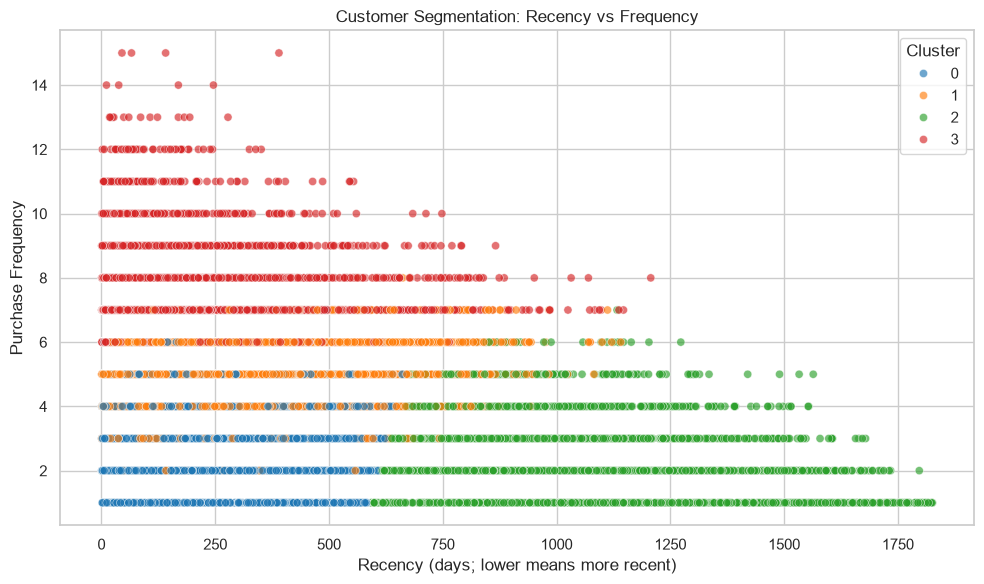

In [16]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=rfm,
    x="Recency",
    y="Frequency",
    hue="Cluster",
    palette="tab10",
    alpha=0.65,
    s=35
)

plt.title("Customer Segmentation: Recency vs Frequency")
plt.xlabel("Recency (days; lower means more recent)")
plt.ylabel("Purchase Frequency")
plt.legend(title="Cluster")
plt.tight_layout()
plt.show()

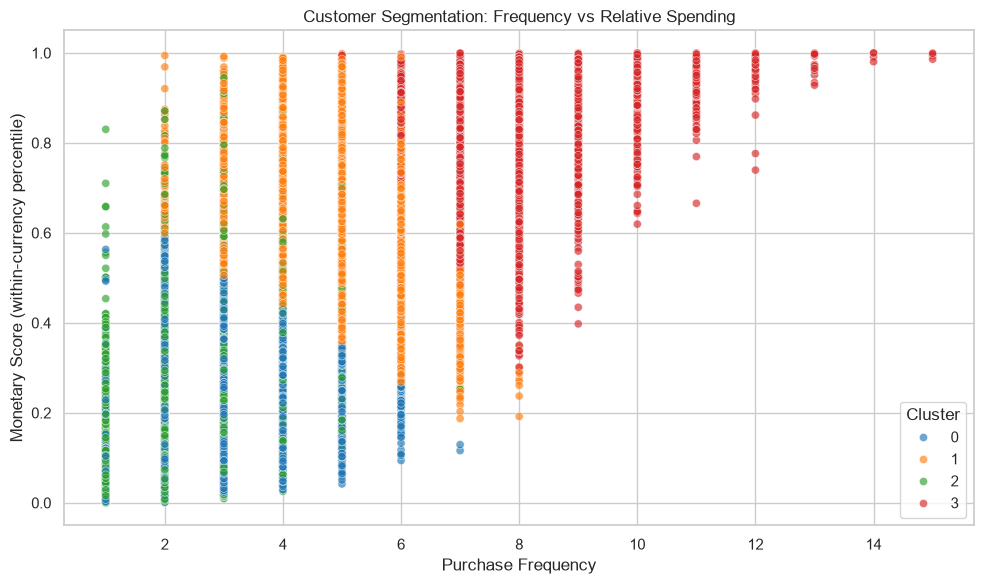

In [17]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=rfm,
    x="Frequency",
    y="Monetary_Score",
    hue="Cluster",
    palette="tab10",
    alpha=0.65,
    s=35
)

plt.title("Customer Segmentation: Frequency vs Relative Spending")
plt.xlabel("Purchase Frequency")
plt.ylabel("Monetary Score (within-currency percentile)")
plt.legend(title="Cluster")
plt.tight_layout()
plt.show()

In [18]:
cluster_profile = rfm.groupby("Cluster").agg(
    Customer_Count=("customer_id", "nunique"),
    Average_Recency=("Recency", "mean"),
    Average_Frequency=("Frequency", "mean"),
    Average_Monetary_Score=("Monetary_Score", "mean"),
    Average_Purchase_Value=("Average_Purchase_Value", "mean"),
    Average_CLV=("Customer_Lifetime_Value", "mean")
).round(2)

cluster_profile["Customer_Percentage"] = (
    cluster_profile["Customer_Count"]
    / cluster_profile["Customer_Count"].sum()
    * 100
).round(2)

display(cluster_profile)

,Customer_Count,Average_Recency,Average_Frequency,Average_Monetary_Score,Average_Purchase_Value,Average_CLV,Customer_Percentage
Cluster,,,,,,,
0,6957,256.82,3.18,0.23,956.65,4730.05,28.11
1,8604,274.03,4.89,0.63,1463.77,8696.18,34.77
2,3978,993.51,2.57,0.25,1207.20,4937.06,16.07
3,5209,176.88,7.53,0.84,1414.06,12383.86,21.05


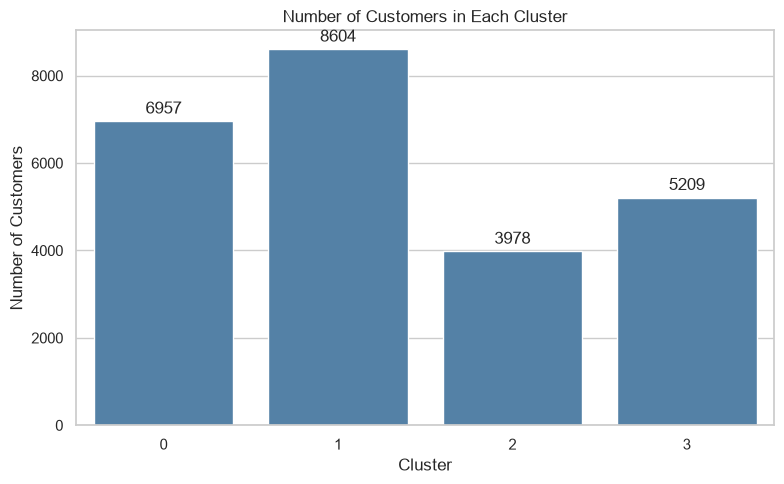

In [19]:
cluster_counts = rfm["Cluster"].value_counts().sort_index()

plt.figure(figsize=(8, 5))

ax = sns.barplot(
    x=cluster_counts.index.astype(str),
    y=cluster_counts.values,
    color="steelblue"
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.0f", padding=3)

plt.title("Number of Customers in Each Cluster")
plt.xlabel("Cluster")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

In [20]:
rfm.to_csv("C:/Users/hp/Desktop/Practice/Data_Analysis/archive/customer_segments.csv", index=False)

cluster_profile.to_csv("C:/Users/hp/Desktop/Practice/Data_Analysis/archive/cluster_profile.csv")

print("Saved customer_segments.csv")
print("Saved cluster_profile.csv")

Saved customer_segments.csv
Saved cluster_profile.csv
